# Zadanie 1 Kwiatki

### 1.1

Index(['sepal length', 'sepal width', 'petal length', 'petal width'], dtype='str')
Min:  2.0
Max:  4.4


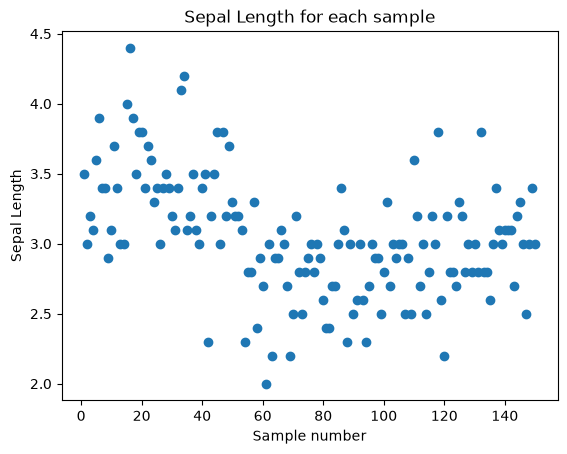

In [21]:
from ucimlrepo import fetch_ucirepo 
import matplotlib.pyplot as plt

# fetch dataset 
iris = fetch_ucirepo(id=53) 
  
# data (as pandas dataframes) 
X = iris.data.features 
y = iris.data.targets 
  
# metadata 
#print(iris.metadata) 
  
# variable information 
#print(iris.variables) 
print(X.columns)
sepal_lenght = X["sepal length"]
print("Min: ", sepal_lenght.min())
print("Max: ", sepal_lenght.max())
#print("Unique:")
#print(sepal_lenght.unique())
data_sample = range(1, len(sepal_lenght)+1)
plt.scatter(data_sample, sepal_lenght)
plt.xlabel("Sample number")
plt.ylabel("Sepal Length")
plt.title("Sepal Length for each sample")
plt.show()
#Nie ma sensu łaczyc kropek bo dane nie sa zależe od siebie jak np temperatura w czasie.

### 1.2

sepal width
<2.5        1
2.5-3.0     1
3.0-3.5    27
3.5-4.0    17
>=4.0       4
Name: count, dtype: int64


(array([0, 1, 2, 3, 4]),
 [Text(0, 0, '<2.5'),
  Text(1, 0, '2.5-3.0'),
  Text(2, 0, '3.0-3.5'),
  Text(3, 0, '3.5-4.0'),
  Text(4, 0, '>=4.0')])

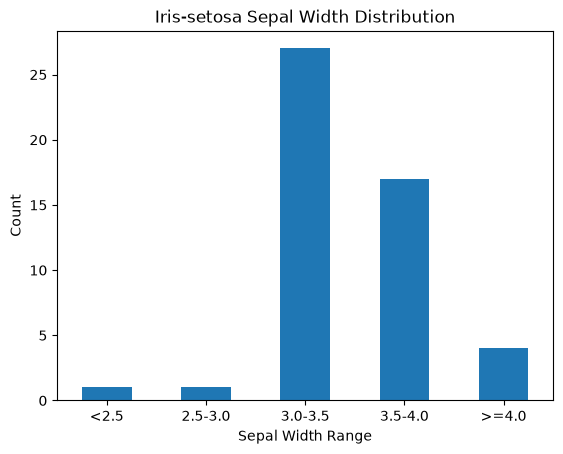

In [48]:
import pandas as pd

setosa = X.loc[y["class"] == "Iris-setosa", "sepal width"]
bins = [-float("inf"), 2.5, 3.0, 3.5 , 4.0, float("inf")]
labels = ["<2.5", "2.5-3.0", "3.0-3.5", "3.5-4.0", ">=4.0"]
groups = pd.cut(setosa, bins=bins, labels=labels, right=False)
count = groups.value_counts().sort_index()

print(count)

count.plot(kind="bar")
plt.xlabel("Sepal Width Range")
plt.ylabel("Count")
plt.title("Iris-setosa Sepal Width Distribution")
plt.xticks(rotation=0)



### 1.3


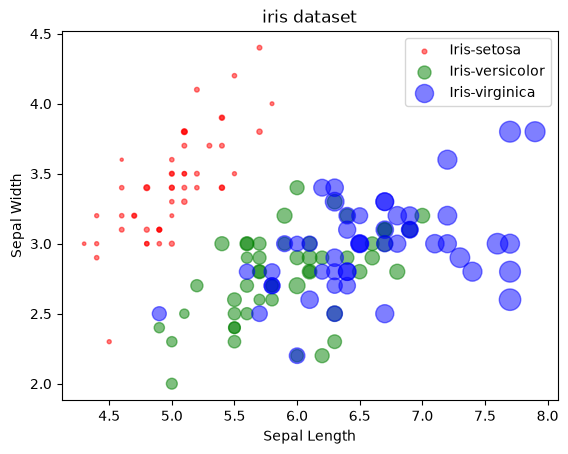

In [45]:
colors = {"Iris-setosa": "red", "Iris-versicolor": "green", "Iris-virginica": "blue"}

for species, color in colors.items():
    mask = y["class"] == species
    plt.scatter(X.loc[mask, "sepal length"],
                X.loc[mask, "sepal width"],
                s=X.loc[mask, "petal length"] **2*5,
                color=color, 
                label=species,
                alpha=0.5)
plt.xlabel("Sepal Length")
plt.ylabel("Sepal Width")
plt.title("iris dataset")
plt.legend()
plt.show()

### 1.4

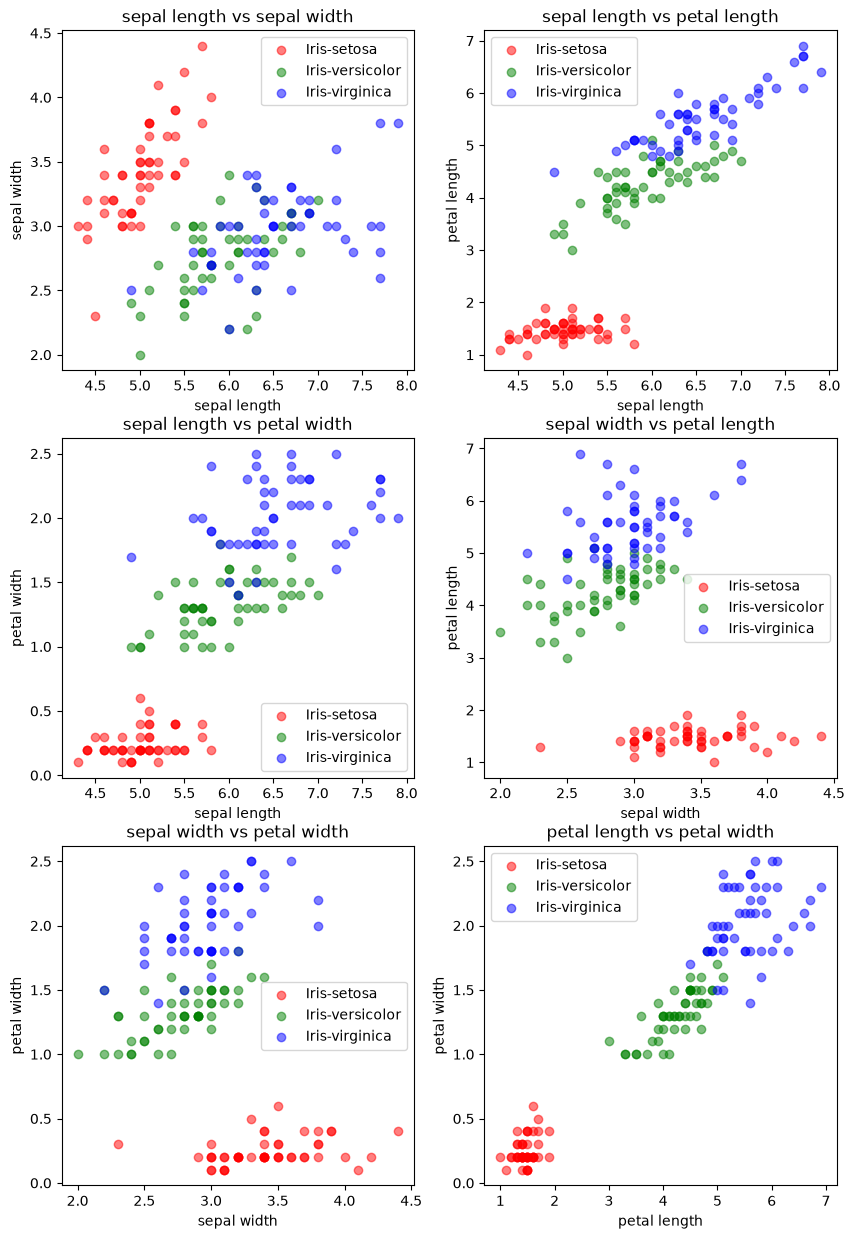

In [56]:
from itertools import combinations
attributes = list(X.columns)
pairs = list(combinations(attributes, 2))

figures, axes = plt.subplots(nrows=3, ncols=2, figsize=(10, 15))

for num_wyk, (x_atr, y_atr) in zip(axes.flat, pairs):
    for species, color in colors.items():
        mask = y["class"] == species
        num_wyk.scatter(X.loc[mask, x_atr],
                X.loc[mask, y_atr],
                #s=X.loc[mask, "petal length"] **2*3,
                color=color, 
                label=species,
                alpha=0.5)
        num_wyk.set_xlabel(x_atr)
        num_wyk.set_ylabel(y_atr)
        num_wyk.legend()
        num_wyk.set_title(f"{x_atr} vs {y_atr}")
plt.show()

### 1.5


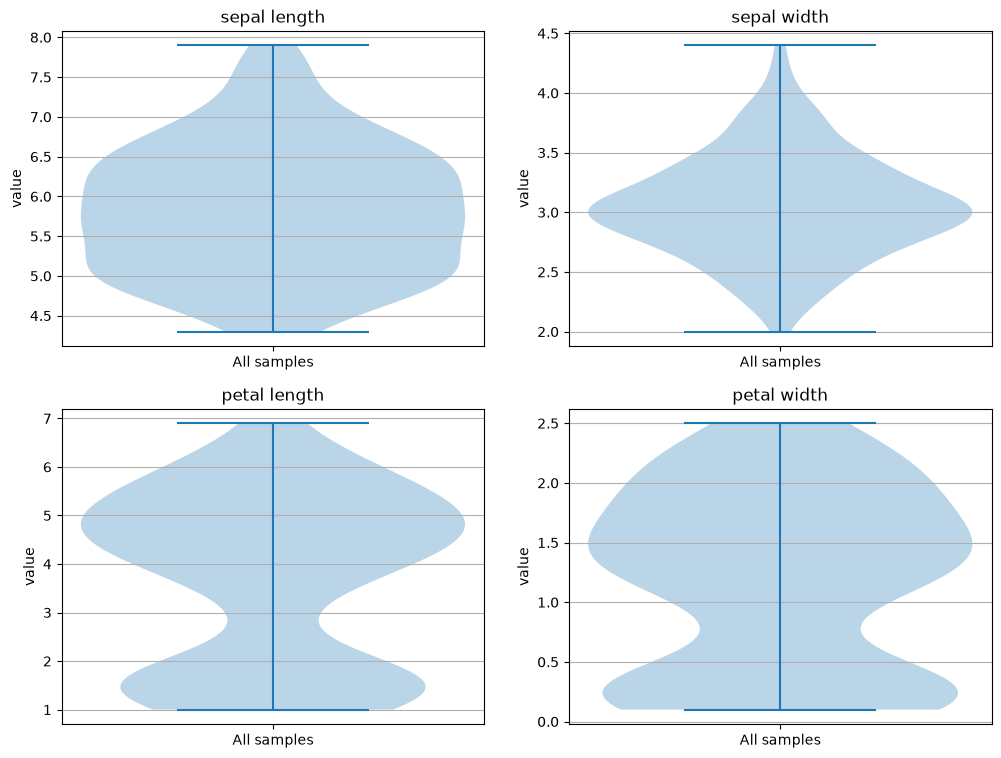

In [81]:
figures, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, attribute in zip(axes.flat, X.columns):
    ax.violinplot(X[attribute])
    ax.set_title(attribute)
    ax.set_ylabel("value")
    ax.set_xticks([1])
    ax.set_xticklabels(["All samples"])
    ax.grid(axis="y")

plt.show()

# Zadanie 2


### 2.1

In [98]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
bank_marketing = fetch_ucirepo(id=222) 
  
# data (as pandas dataframes) 
X = bank_marketing.data.features 
y = bank_marketing.data.targets 
  
# metadata 
#print(bank_marketing.metadata) 
  
# variable information 
#print(bank_marketing.variables) 


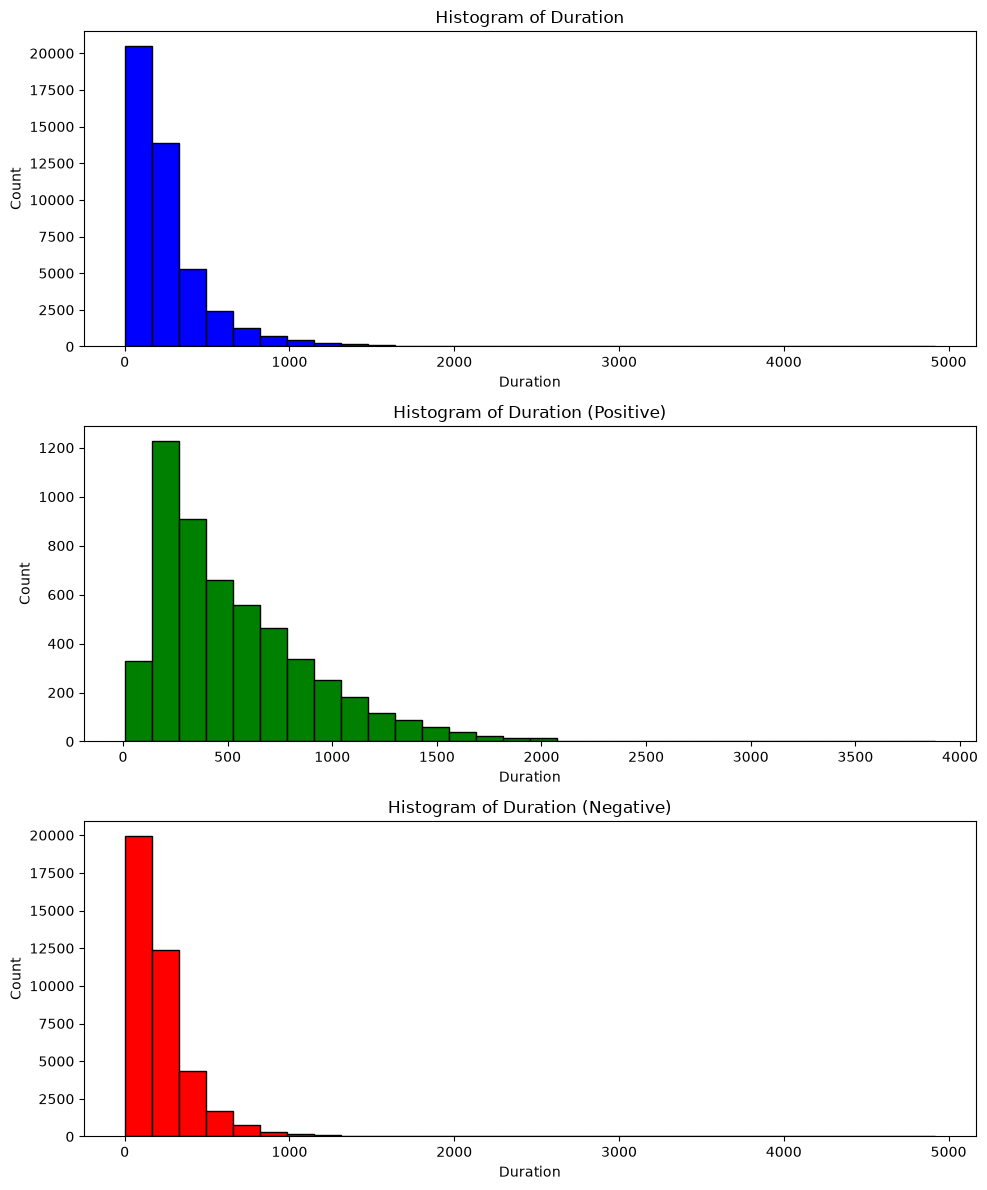

In [112]:
_, axes = plt.subplots(3, 1, figsize=(10, 12))
axes[0].hist(X["duration"], bins=30, color="blue", edgecolor="black")
axes[0].set_title("Histogram of Duration")
axes[0].set_xlabel("Duration")
axes[0].set_ylabel("Count")

axes[1].hist(X.loc[y["y"] == "yes", "duration"], bins=30, color="green",edgecolor="black")
axes[1].set_title("Histogram of Duration (Positive)")
axes[1].set_xlabel("Duration")
axes[1].set_ylabel("Count")

axes[2].hist(X.loc[y["y"] == "no", "duration"], bins=30, color="red", edgecolor="black")
axes[2].set_title("Histogram of Duration (Negative)")
axes[2].set_xlabel("Duration")
axes[2].set_ylabel("Count")

plt.tight_layout()

### 2.2


In [121]:
import ipywidgets as widgets
from ipywidgets import interact

#plt.hist(X.loc[X["age"]> 25, "balance"], bins=30,  color="purple", edgecolor="black")
#plt.xlabel("Balance")
#plt.ylabel("Count")
#plt.title("Histogram of Balance for Age > 25")
#plt.show()



def show_histogram(age_limit):
    plt.hist(X.loc[X["age"] > age_limit, "balance"], bins=30, color="purple", edgecolor="black")
    plt.xlabel("Balance")
    plt.ylabel("Count")
    plt.title(f"Histogram of Balance for Age > {age_limit}")
    plt.show()

age_slider = widgets.IntSlider(value=25, min=X["age"].min(), max=X["age"].max(), step=1, description='Age Limit:')

interact(show_histogram, age_limit=age_slider)

interactive(children=(IntSlider(value=25, description='Age Limit:', max=95, min=18), Output()), _dom_classes=(…

<function __main__.show_histogram(age_limit)>

### 2.3


In [133]:
t= 360
mask = X["duration"] > t
data = y.loc[mask, "y"]
all_count = len(data)

all_positive_count = (data == "yes").sum()

procentage_positive = (all_positive_count / all_count) * 100
print("All samples with duration > 360 seconds: ", all_count)
print("All positive samples with duration > 360 seconds: ", all_positive_count)
print(f"Percentage of positive samples with duration > 360 seconds: {procentage_positive:.2f} %")

All samples with duration > 360 seconds:  9354
All positive samples with duration > 360 seconds:  3046
Percentage of positive samples with duration > 360 seconds: 32.56 %


All samples with duration > 360 seconds: 9354
Positive samples with duration > 360 seconds: 3046
Percentage of positive samples: 32.56%


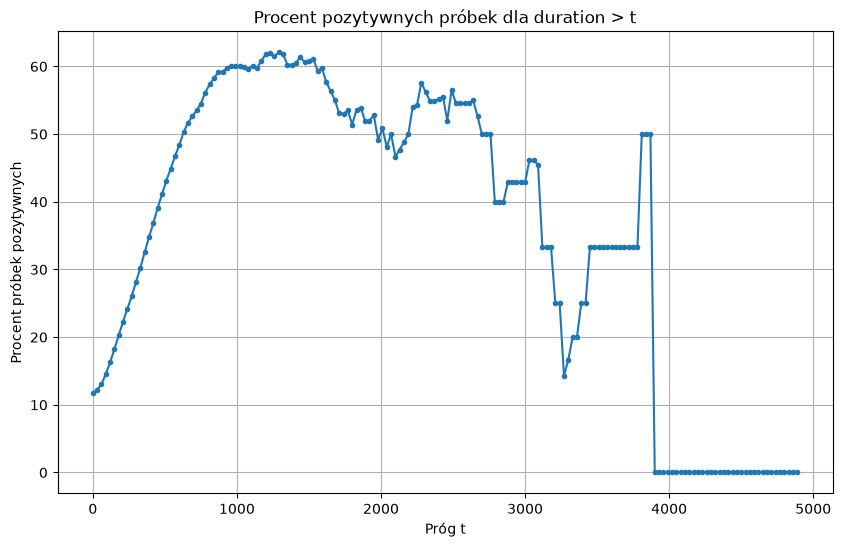

In [129]:
def show_results(t):
    mask = X["duration"] > t
    data = y.loc[mask, "y"]

    all_count = len(data)
    all_positive_count = (data == "yes").sum()
    percentage_positive = all_positive_count / all_count * 100

    print(f"All samples with duration > {t} seconds: {all_count}")
    print(f"Positive samples with duration > {t} seconds: {all_positive_count}")
    print(f"Percentage of positive samples: {percentage_positive:.2f}%")

    thresholds = range(0, X["duration"].max() + 1, 30)
    percentages = []

    for threshold in thresholds:
        threshold_mask = X["duration"] > threshold
        threshold_data = y.loc[threshold_mask, "y"]
        percentage = (threshold_data == "yes").mean() * 100
        percentages.append(percentage)

    plt.figure(figsize=(10, 6))
    plt.plot(list(thresholds), percentages, marker=".")
    plt.xlabel("Próg t")
    plt.ylabel("Procent próbek pozytywnych")
    plt.title("Procent pozytywnych próbek dla duration > t")
    plt.grid()
    plt.show()


show_results(360)

### 2.4

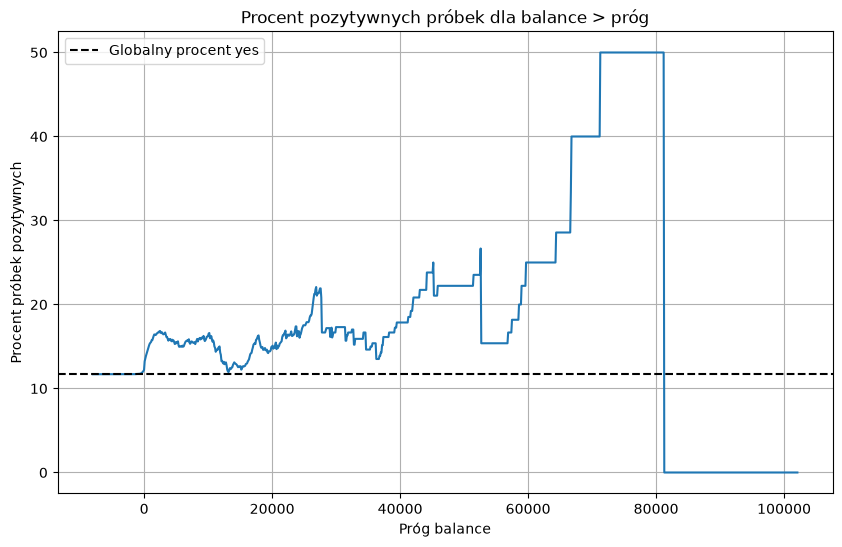

interactive(children=(IntSlider(value=0, description='Balance:', max=102127, min=-8019, step=10), Output()), _…

<function __main__.show_balance_results(balance_threshold)>

In [144]:
global_positive_percentage = (y["y"] == "yes").mean() * 100

min_balance = int(X["balance"].min())
max_balance = int(X["balance"].max())
thresholds = range(min_balance, max_balance + 1, 100)
percentages = []

for threshold in thresholds:
    mask = X["balance"] > threshold
    data = y.loc[mask, "y"]
    percentages.append((data == "yes").mean() * 100)

plt.figure(figsize=(10, 6))
plt.plot(list(thresholds), percentages)
plt.axhline(
    global_positive_percentage,
    color="black",
    linestyle="--",
    label="Globalny procent yes"
)
plt.xlabel("Próg balance")
plt.ylabel("Procent próbek pozytywnych")
plt.title("Procent pozytywnych próbek dla balance > próg")
plt.legend()
plt.grid()
plt.show()


def show_balance_results(balance_threshold):
    mask = X["balance"] > balance_threshold
    data = y.loc[mask, "y"]

    if len(data) == 0:
        print("Brak próbek powyżej tego progu.")
        return

    positive_count = (data == "yes").sum()
    percentage_positive = positive_count / len(data) * 100

    print(f"Samples with balance > {balance_threshold}: {len(data)}")
    print(f"Positive samples: {positive_count}")
    print(f"Percentage for this threshold: {percentage_positive:.2f}%")
    print(f"Global percentage of positive samples: {global_positive_percentage:.2f}%")


slider = widgets.IntSlider(
    value=0,
    min=min_balance,
    max=max_balance,
    step=10,
    description="Balance:"
)

interact(show_balance_results, balance_threshold=slider)

### 2.5


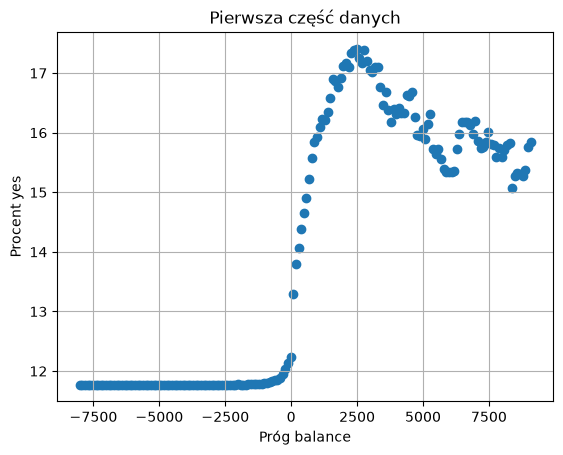

Wybrany próg: 2481
Pierwsza część: (np.int64(2837), np.int64(2063), np.float64(82.59097525473071), np.float64(77.52724539646749))
Druga część: (np.int64(2917), np.int64(2060), np.float64(83.70157819225251), np.float64(78.38660578386606))


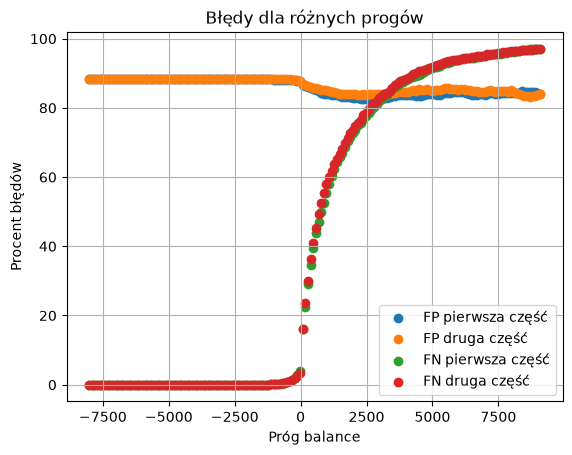

In [154]:
X_first = X.sample(frac=0.5, random_state=42)
X_second = X.drop(X_first.index)
y_first = y.loc[X_first.index]
y_second = y.loc[X_second.index]

thresholds = range(
    int(X_first["balance"].min()),
    int(X_first["balance"].max()) + 1,
    100
)
valid_thresholds = []
positive_percentages = []

for threshold in thresholds:
    mask = X_first["balance"] > threshold
    data = y_first.loc[mask, "y"]

    if len(data) >= 500:
        valid_thresholds.append(threshold)
        positive_percentages.append((data == "yes").mean() * 100)

plt.scatter(valid_thresholds, positive_percentages)
plt.xlabel("Próg balance")
plt.ylabel("Procent yes")
plt.title("Pierwsza część danych")
plt.grid()
plt.show()

best_index = positive_percentages.index(max(positive_percentages))
best_threshold = valid_thresholds[best_index]
print("Wybrany próg:", best_threshold)
def errors(X_part, y_part, threshold):
    predicted_positive = X_part["balance"] > threshold
    actual_positive = y_part["y"] == "yes"

    false_positive = (predicted_positive & ~actual_positive).sum()
    false_negative = (~predicted_positive & actual_positive).sum()
    predicted_count = predicted_positive.sum()
    actual_count = actual_positive.sum()

    false_positive_percent = false_positive / predicted_count * 100
    false_negative_percent = false_negative / actual_count * 100

    return false_positive, false_negative, false_positive_percent, false_negative_percent

first_errors = errors(X_first, y_first, best_threshold)
second_errors = errors(X_second, y_second, best_threshold)

print("Pierwsza część:", first_errors)
print("Druga część:", second_errors)

first_fp = []
second_fp = []
first_fn = []
second_fn = []

for threshold in valid_thresholds:
    first = errors(X_first, y_first, threshold)
    second = errors(X_second, y_second, threshold)

    first_fp.append(first[2])
    second_fp.append(second[2])
    first_fn.append(first[3])
    second_fn.append(second[3])

plt.scatter(valid_thresholds, first_fp, label="FP pierwsza część")
plt.scatter(valid_thresholds, second_fp, label="FP druga część")
plt.scatter(valid_thresholds, first_fn, label="FN pierwsza część")
plt.scatter(valid_thresholds, second_fn, label="FN druga część")
plt.xlabel("Próg balance")
plt.ylabel("Procent błędów")
plt.title("Błędy dla różnych progów")
plt.legend()
plt.grid()
plt.show()